# Recommender Systems

**Recommender Systems** are a family of algorithms and approaches to provide suggestions of new items to users based on the user's preferences. The goal is to maximize user interaction, purchases or some other metric by showing the user what they like and hiding items that they dislike. Recommenders are also useful when users are navigating a huge number of options, such as in modern movie libraries or online stores.

There are multiple approaches to recommendation, such as:
- Content-based Filtering
- Collaborative Filtering
- Latent Factor Models

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
import itertools
from tqdm import tqdm

pd.options.mode.chained_assignment = None

## Content-based Filtering

**Content-based Filtering** is a recommendation approach where we examine the user's preferences based on their past behavior (rating items, interacting with items, etc.) and try to suggest similar items to the ones that they've already expressed a preference for. For example, if a user listens to a particular genre of music, we would recommend songs with the same genre or theme.

This is accomplished by first building **item profiles** - grouping similar items together. In our song example, we may transform each song's metadata into a vector containing information about the author, the genre it belongs to, and we may even include the text of the song to group by theme. Then we build a **user profile** based on user's previous ratings and start recommending items similar to what the user has shown a preference for.

#### Item Profiles

For textual data with a limited set of values (e.g. genres), we can use a boolean vector with $1$s for the genres the song belongs to and $0$s elsewhere. However, for richer textual data, we need to extract features that would allow us to group similar items together while keeping different items apart. We can do this using a statistical method called **Term Frequency-Inverse Document Frequency**. The idea is to identify relevant keywords in documents as follows:
- Calculate how often a word occurs in each document (Term Frequency)
- Calculate how rare a word is across the entire corpus of documents (Inverse Document Frequency)

Then we multiply the two together. This is useful in multiple ways:
- When a word occurs frequently in a document, we can consider that word important (High TF)
- However, if it occurs frequently in every document, we can assume it's a common word and not particularly relevant to a specific document (Low IDF)
- Words that occur frequently in a few documents and infrequently in the overall corpus (High TF and High IDF) point to important words that are relevant to the topic of a set of documents, meaning we've found words that group a set of documents together. Thus, words that are useful to distinguish the topic of a document will have a high TF-IDF score.

Let $f_{ij}$ be the frequency of term $i$ in document $j$, $n_i$ be the number of documents that mention term $i$ and $N$ be the total number of documents. Then:

$$
\begin{align}
TF_{ij} &= \frac{f_{ij}}{\max_k f_{kj}} \\
IDF_i &= \log (\frac{N}{n_i}) \\
\text{TF-IDF score: } w_{ij} &= TF_{ij} \times IDF_i
\end{align}
$$

#### User Profiles

Suppose a user has rated items with profiles $i_1, ..., i_n$. Then to build the user profile, we can take a weighted average of each of the item profiles (vectors):

$$
u = \alpha_1 i_1 + ... + \alpha_n i_n
$$

where $\alpha_i$ is the user's rating for item $i$. In practice, we often center the user's ratings around 0 as this helps deal with easy raters and tough raters (people who rate everything higher or lower than usual).

#### Finding Similar Items

Given a user profile $u$ and item profile $i$, we want to calculate how similar the item is to the user's preferences. To do this, we can use **cosine similarity**:

$$
S(u, i) = \frac{u \cdot i}{|u| |i|}
$$

If our vectors are already normalized, this becomes a simple dot product. We want to run this for all items in the library and return the top $K$ most similar items.

#### Pros and Cons

The advantages of this approach is that we don't need other user's data to make predictions and we can also recommend new items (items that haven't been rated by anyone) as we only take into account the similarity between the items the user has liked and the rest of the library.

Unfortunately, feature engineering is quite difficult as users typically don't stick to a particular genre or author, but they have varied tastes. In addition, content-based recommendation suffers from the **cold start problem**, which means we can't recommend to users who haven't rated anything, because we can't build a user profile. This is usually remedied by having a separate set of recommended items to provide to such users based on some other heuristic (e.g. most popular items overall) or we can build an "average" profile from all the users in the system.

In [2]:
df_ratings = pd.read_csv('data/movie_ratings/ratings_small.csv')
df_ratings['userId'] = df_ratings['userId'].astype(str)
df_ratings['movieId'] = df_ratings['movieId'].astype(str)

df_movies = pd.read_csv('data/movie_ratings/movies_metadata.csv')[['id', 'original_title', 'original_language', 'overview']]
df_movies = df_movies[df_movies['original_language'] == 'en'].dropna()

df_movies = df_movies[df_movies['id'].isin(df_ratings['movieId'])]
df_ratings = df_ratings[df_ratings['movieId'].isin(df_movies['id'])]

df_movies = df_movies.drop_duplicates().reset_index(drop=True)
df_ratings = df_ratings.drop_duplicates().reset_index(drop=True)

/var/folders/1m/clk0pq4d2v524wngfdmlkh7r0000gn/T/ipykernel_60523/2506478340.py:5: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df_movies = pd.read_csv('data/movie_ratings/movies_metadata.csv')[['id', 'original_title', 'original_language', 'overview']]


In [3]:
def content_filtering(df_movies, df_ratings):
    # build movie profiles based on the description of the movie
    corpus = df_movies['overview'].tolist()
    tfidf = TfidfVectorizer(stop_words='english', max_features=15000, norm='l2')
    X = tfidf.fit_transform(corpus)

    # use Bayesian-adjusted mean to find best cold start items
    global_prior = df_ratings['rating'].mean()
    prior_weight = 20
    mean_rating_per_movie = df_ratings.groupby('movieId')['rating'].mean()
    n_ratings_per_movie = df_ratings.groupby('movieId')['rating'].size()
    cold_start_items = (n_ratings_per_movie * mean_rating_per_movie / (n_ratings_per_movie + prior_weight) + prior_weight * global_prior / (n_ratings_per_movie + prior_weight))
    cold_start_items = cold_start_items.reset_index()
    cold_start_items = pd.merge(
        df_movies,
        cold_start_items,
        left_on=['id'],
        right_on=['movieId'],
        how='inner'
    )
    cold_start_items = cold_start_items.rename(columns={'rating': 'predicted_rating'}).sort_values('predicted_rating', ascending=False)
    cold_start_items = cold_start_items[['id', 'original_title', 'predicted_rating']]

    df_movies_subset = df_movies.drop(columns=['original_language', 'overview'])
    rating_mean = df_ratings['rating'].mean()

    def predict(user_id, top_k=10):
        user = df_ratings[df_ratings['userId'] == user_id]
        if user.shape[0] == 0:
            # handle cold start
            return cold_start_items.head(top_k)

        # center weights for the user
        # this uses the global mean rating to handle users who rate everything the same, otherwise their user profile would be all 0s
        user['rating_norm'] = user['rating'] - rating_mean

        user_movies_idx = df_movies[df_movies['id'].isin(user['movieId'])].index
        user_movies = X[user_movies_idx].todense()
        user_ratings = user['rating_norm'].to_numpy()
        # take weighted average of the user's preferences
        user_profile = np.dot(user_ratings, user_movies) / np.abs(user_ratings).sum()
        # normalize to unit length
        user_profile = user_profile / np.linalg.norm(user_profile)

        # calculate similarity for the movie library
        preds = pd.DataFrame((user_profile @ X.T).tolist()[0], columns=['similarity']).reset_index(names='movieIdx')        
        # remove items the user has rated already
        preds = preds[~preds['movieIdx'].isin(user_movies_idx)]
        
        # post-process and calculate predicted ratings
        preds_merged = pd.merge(
            preds,
            df_movies_subset,
            left_index=True,
            right_index=True
        )
        mean_sim = preds_merged['similarity'].mean()
        rating_std = user['rating'].std()
        sim_std = preds_merged['similarity'].std()
        s = rating_std / (sim_std + 0.5)

        user_avg_rating = user['rating'].mean()
        preds_merged['predicted_rating'] = (preds_merged['similarity'] - mean_sim) * s + user_avg_rating
        preds_merged['predicted_rating'] = np.clip(preds_merged['predicted_rating'], 0., 5.)
        preds_merged = preds_merged.sort_values('predicted_rating', ascending=False)
        return preds_merged.sort_values('similarity', ascending=False).head(top_k)[['id', 'original_title', 'predicted_rating']]
    return predict

predict = content_filtering(df_movies, df_ratings)

In [4]:
predict(user_id='10', top_k=10)

,id,original_title,predicted_rating
570,1497,Teenage Mutant Ninja Turtles II: The Secret of...,3.811213
1692,55245,!Women Art Revolution,3.752146
569,1498,Teenage Mutant Ninja Turtles,3.751713
1398,1273,TMNT,3.720215
1164,437,Cube 2: Hypercube,3.703592
937,1807,Elephant,3.698112
1014,42015,Swimming to Cambodia,3.698098
1595,31156,Dante's Hell Animated,3.694990
1233,1444,Junebug,3.691648
64,8831,Timecop,3.691229


## Collaborative Filtering

**Collaborative Filtering** is a family of recommendation algorithms that predict a user's preferences by leveraging the collective behavior of many users. The underlying idea is that users with similar tastes in the past will continue to prefer similar items in the future.

There are two main paradigms:
- **User–User CF**: Find users similar to a target user, and recommend items those similar users have liked.
- **Item–Item CF**: Find items similar to those the target user has rated highly, and recommend those similar items.

In practice, item–item CF is often preferred because:
- The number of items is typically smaller and more stable than the number of users.
- Item relationships are more persistent (users' tastes change, but movies or products don't).
- Precomputing item–item similarities allows very fast, on-demand recommendations.

We represent the data as a user–item rating matrix $X$:

$$
X_{ij} = \begin{cases}
r_{ij} & \text{ if user j rated item i} \\
NaN & \text{ if not rated}
\end{cases}
$$

Here, rows correspond to items, columns to users and entries represent the user's rating. The matrix is usually sparse since most users rate only a small fraction of items.

The overall process is as follows:

1. Center ratings around $0$ - this handles users that rate differently (easy raters vs. tough raters) and makes data comparable across items due to relative preference

$$
\tilde{X}_{ij} = X_{ij} - \bar{X}_i
$$

2. Normalize each item vector to unit length so that we can later compute cosine similarity using simple dot products. This also removes the influence of magnitude (popular movies rated by many people vs. obscure movies with few ratings)

$$
\hat{X}_i = \frac{\tilde{X}_i}{||\tilde{X}_i||}
$$

3. Compute similarities. We create a similarity matrix where each entry is the similarity between two items $i$ and $j$:

$$
S_{ij} = \frac{\sum_{u \in U_{ij}} \tilde{X}_{iu} \tilde{X}_{ju}}{\sqrt{\sum_{u \in U_{ij}} \tilde{X}_{iu}^2} \sqrt{\sum_{u \in U_{ij}} \tilde{X}_{ju}^2}}
$$

where $U_{ij}$ is the set of users who rated both items $i$ and $j$. This is equivalent to **centered cosine similarity** (also **Pearson correlation**) between 2 vectors. In practice, this can be computed efficiently using masked matrix operations — filling NaNs with zeros and multiplying only over overlapping users.

4. Predict ratings

Given a user $u$, we want to predict how they would rate an unseen item $i$:
- Find items $j$ that the user has rated and that are similar to $i$
- Select the top $k$ most similar items to $i$ (nearest neighbors)
- Compute a weighted average of the user's ratings for those similar items:

$$
\hat{r}_{ui} = \frac{ \sum_{j \in N_k(i)} S_{ij}r_{uj} }{ \sum_{j \in N_k(i)} |S_{ij}| }
$$

5. Recommend top $k$ items. For each user:
- Exclude items they have already rated.
- Predict ratings for all remaining items.
- Sort these predicted ratings in descending order.
- Recommend the top $k$ highest-scoring items.

#### Pros

Item-item CF is more scalable than user-user CF as it can be pre-computed once and then reused. It also doesn't require explicit item features, it just uses observed user behavior.

#### Cons

Cold start remains a problem. We can't recommend easily to new users and we can't recommend items that have no ratings.

In [5]:
def collaborative_filtering(df_movies, df_ratings):
    """
    Item-to-item collaborative filtering
    """
    def cols_to_tuple(group):
        return (np.array(group['movieId'].tolist()), np.array(group['rating'].tolist()))
    
    ratings_grouped = df_ratings.groupby('movieId')['rating'].size()
    # remove items that have a single rating - this provides no information
    ratings_grouped = ratings_grouped[ratings_grouped > 1]
    X = df_ratings[df_ratings['movieId'].isin(ratings_grouped.index)]
    # create movie-user matrix
    X = X.pivot(index='movieId', columns='userId', values='rating')
    movie_ids = X.index.to_numpy()
    X = X.to_numpy()

    X_masked = np.ma.array(X, mask=np.isnan(X))
    # center ratings for each movie
    X_masked = X_masked - np.mean(X_masked, axis=1).reshape(-1, 1)
    X_norms = np.sqrt(np.sum(np.square(X_masked), axis=1))[:, None]
    # normalize each movie vector
    X_masked = (X_masked / X_norms)

    # create a mask of user-movie ratings
    M = (~np.isnan(X_masked)).astype(int)
    # compute the number of ratings each movie got
    C = np.dot(M, M.T)
    # temporarily replace NaNs with 0s
    R = np.where(np.isnan(X_masked), 0., X_masked)
    # compute the matrix of similarities
    S = np.dot(R, R.T)
    # set similarities to 0 where there is no overlap between users rating them
    S = np.where(C == 0, 0., S)
    # fill diagonals with 1s
    np.fill_diagonal(S, 1.)

    user_movie_rating_dict = df_ratings.groupby('userId').apply(cols_to_tuple, include_groups=False).to_dict()

    def predict(user_id, n_neigh=5, top_k=10):
        user_movies, user_ratings = user_movie_rating_dict[user_id]
        rated_idx = np.nonzero(np.isin(movie_ids, user_movies))[0]
        user_movies = set(user_movies.tolist())

        preds = []
        for i, movie_id in enumerate(movie_ids):
            # skip movies already rated by the user
            if movie_id in user_movies:
                continue
            # similarities between this movie and all movies the user rated
            sim_row = S[i, rated_idx]
            # pick top-k similar movies
            n_neigh_idx = np.argsort(sim_row)[-n_neigh:]
            n_neigh_sims = sim_row[n_neigh_idx]
            n_neigh_ratings = user_ratings[n_neigh_idx]
        
            # ignore zero or negative similarities
            mask = n_neigh_sims > 0
            if np.sum(mask) == 0:
                pred = np.nan
            else:
                # weighted average of user's ratings
                pred = np.sum(n_neigh_sims[mask] * n_neigh_ratings[mask]) / np.sum(n_neigh_sims[mask])
            preds.append((movie_id, pred))
            
        df_preds = pd.DataFrame(preds, columns=['movie_id', 'predicted_rating']).dropna().sort_values('predicted_rating', ascending=False).head(top_k)
        df_preds = pd.merge(
            df_preds,
            df_movies,
            left_on=['movie_id'],
            right_on=['id']
        )[['id', 'original_title', 'predicted_rating']]
        return df_preds
    
    return predict     

In [6]:
predict = collaborative_filtering(df_movies, df_ratings)

In [7]:
predict(user_id='10')

,id,original_title,predicted_rating
0,8093,Khadak,5.000000
1,242,The Godfather: Part III,4.972658
2,213,North by Northwest,4.947676
3,27850,Halloweentown,4.774606
4,2149,Body of Evidence,4.766604
5,178,Blown Away,4.716724
6,2690,Irma la Douce,4.701807
7,232,Rumble Fish,4.670463
8,340,Everything is Illuminated,4.666858
9,2162,Chill Factor,4.653483


## Latent Factor Recommenders

In [30]:
class LatentFactorsModel:
    def __init__(self, lr=0.0001, eps=1e-5, max_iter=10000, alpha=0):
        self.lr = lr
        self.alpha = alpha
        self.eps = eps
        self.max_iter = max_iter
        self.losses = []
        self.item_idx = None
        self.user_idx = None
        self.users_seen_items = None
        self.Q = None
        self.P = None

    def fit(self, X, k=20):
        self.item_idx = X.index.to_numpy()
        self.user_idx = X.columns.to_numpy()
        X = X.to_numpy()
        self.users_seen_items = {
            self.user_idx[u]: self.item_idx[np.where(~np.isnan(X[:, u]))[0]]
            for u in range(X.shape[1])
        }
        Q = np.random.normal(size=(X.shape[0], k), loc=0, scale=0.01)
        P = np.random.normal(size=(X.shape[1], k), loc=0, scale=0.01)
        X = np.ma.array(X, mask=np.isnan(X))
        best_loss = np.inf
        i = 0
        while True:
            loss = self._loss(X, Q, P)
            self.losses.append(loss.item())
            grad_Q, grad_P = self._compute_grad(X, Q, P)
            Q = Q - self.lr * grad_Q
            P = P - self.lr * grad_P
            if np.abs(best_loss - loss) < self.eps or i >= self.max_iter:
                self.Q = Q
                self.P = P
                break
            best_loss = loss
            i += 1
        return self

    def predict(self, user_id, top_k=10):
        user_index = np.where(self.user_idx == user_id)[0]
        P_u = self.P[user_index]
        preds = np.dot(self.Q, P_u.T).reshape(1, -1)[0]
        preds_sort_idx = np.argsort(preds)[::-1]
        preds_sorted = preds[preds_sort_idx]
        items = self.item_idx[preds_sort_idx]
        seen = lfm.users_seen_items[user_id]
        seen_idx = ~np.isin(items, seen)
        preds_sorted = preds_sorted[seen_idx][:top_k]
        preds_sorted = np.clip(preds_sorted, 0., 5.)
        items = items[seen_idx][:top_k]
        return items, preds_sorted

    def _loss(self, X, Q, P):
        # fill masked values with 0 so they don't contribute to loss computation
        X_filled = X.filled(0)
        # create a mask with 1 for observed entries and 0 for missing
        mask = (~X.mask).astype(float)
        R = Q @ P.T
        error = (X_filled - R) * mask
        # apply regularization term if alpha > 0
        loss = np.sum(error ** 2) + self.alpha * (np.sum(Q ** 2) + np.sum(P ** 2))
        return loss

    def _compute_grad(self, X, Q, P):
        # fill masked values with 0 so they don't contribute to gradient computation
        X_filled = X.filled(0)
        # create a mask with 1 for observed entries and 0 for missing
        mask = (~X.mask).astype(float)
        R = Q @ P.T
        # keep residuals only for known entries
        A = -2 * (X_filled - R) * mask
        # apply gradient of regularization term if alpha > 0
        grad_Q = (A @ P) + 2 * self.alpha * Q
        grad_P = (A.T @ Q) + 2 * self.alpha * P
        return grad_Q, grad_P

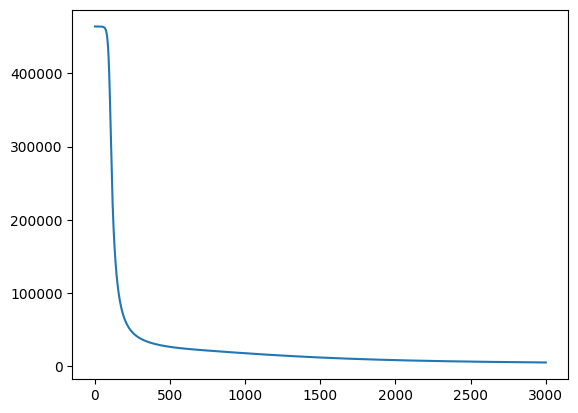

In [31]:
X = df_ratings.pivot(index='movieId', columns='userId', values='rating')
lfm = LatentFactorsModel(max_iter=3000).fit(X)
plt.plot(lfm.losses);

In [36]:
user_id = '10'
recommended_items, predicted_ratings = lfm.predict(user_id=user_id)
pred_movies = df_movies.set_index('id').loc[recommended_items][['original_title']]
pred_movies['predicted_rating'] = predicted_ratings
pred_movies.reset_index()

,id,original_title,predicted_rating
0,759,Gentlemen Prefer Blondes,5.000000
1,65188,Leben nach Microsoft,5.000000
2,4518,Elizabeth,5.000000
3,1649,Bill & Ted's Bogus Journey,5.000000
4,565,The Ring,4.994283
5,4380,Shall We Dance?,4.953769
6,301,Rio Bravo,4.944174
7,42418,Young Black Stallion,4.941683
8,1428,Once Upon a Time in Mexico,4.924749
9,80,Before Sunset,4.923451
